# ITBI x criminalidade por bairro — São Paulo

Análise exploratória inspirada na EDA de referência: cruza transações residenciais do ITBI com boletins de ocorrência por bairro e ano (2022–2025). A variável de preço é o valor declarado por m² construído, corrigido pelo IPCA para reais de dezembro de 2025; criminalidade é o número de BOs distintos. A análise mede associação entre bairros, não efeito causal. Não há denominador populacional, então contagens de crime não são taxas de risco.

O deflator usa o IPCA acumulado de dezembro a dezembro por ano, logo é uma aproximação para transações ocorridas em diferentes meses do mesmo ano. A junção usa nomes de bairro normalizados (caixa, acentos e pontuação), sem correspondência aproximada. Os resultados devem ser interpretados junto com a cobertura de bairros e o tamanho da amostra.

In [1]:
from pathlib import Path
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "data").is_dir())
DATA_DIR = PROJECT_ROOT / "data"
YEARS = [2022, 2023, 2024, 2025]

ITBI_FILES = {
    2022: next((DATA_DIR / "itbi_sp").glob("*12-2022*.xlsx")),
    2023: next((DATA_DIR / "itbi_sp").glob("*2023*.xlsx")),
    2024: next((DATA_DIR / "itbi_sp").glob("*2024*.xlsx")),
    # Esta é a versão mais recente; não carregar também a outra planilha de 2025.
    2025: next((DATA_DIR / "itbi_sp").glob("*28012026*.xlsx")),
}
ITBI_COLUMNS = [
    "Bairro", "Natureza de Transação",
    "Valor de Transação (declarado pelo contribuinte)", "Data de Transação",
    "Proporção Transmitida (%)", "Área Construída (m2)",
    "Descrição do uso (IPTU)",
]
ITBI_2024_COLUMNS = [
    "N° do Cadastro (SQL)", "Nome do Logradouro", "Número", "Complemento", "Bairro",
    "Referência", "CEP", "Natureza de Transação",
    "Valor de Transação (declarado pelo contribuinte)", "Data de Transação",
    "Valor Venal de Referência", "Proporção Transmitida (%)",
    "Valor Venal de Referência (proporcional)", "Base de Cálculo adotada",
    "Tipo de Financiamento", "Valor Financiado", "Cartório de Registro",
    "Matrícula do Imóvel", "Situação do SQL", "Área do Terreno (m2)", "Testada (m)",
    "Fração Ideal", "Área Construída (m2)", "Uso (IPTU)",
    "Descrição do uso (IPTU)", "Padrão (IPTU)", "Descrição do padrão (IPTU)", "ACC (IPTU)",
]

itbi_parts = []
for year, path in ITBI_FILES.items():
    with pd.ExcelFile(path) as workbook:
        monthly_sheets = [sheet for sheet in workbook.sheet_names if "_" not in sheet and "-" in sheet]
        for sheet in monthly_sheets:
            header = pd.read_excel(workbook, sheet_name=sheet, nrows=0)
            if "Bairro" in header.columns:
                part = pd.read_excel(workbook, sheet_name=sheet, usecols=ITBI_COLUMNS)
            else:
                part = pd.read_excel(workbook, sheet_name=sheet, header=None, usecols=[4, 7, 8, 9, 11, 22, 24])
                part.columns = [
                    "Bairro", "Natureza de Transação",
                    "Valor de Transação (declarado pelo contribuinte)", "Data de Transação",
                    "Proporção Transmitida (%)", "Área Construída (m2)",
                    "Descrição do uso (IPTU)",
                ]
            part["arquivo_ano"] = year
            itbi_parts.append(part)

itbi = pd.concat(itbi_parts, ignore_index=True)

crime_parts = []
for year in YEARS:
    path = next((DATA_DIR / "crime_sp").glob(f"*{year}*.xlsx"))
    with pd.ExcelFile(path) as workbook:
        crime_sheets = [sheet for sheet in workbook.sheet_names if sheet.startswith(("JAN-", "JUL-"))]
        for sheet in crime_sheets:
            part = pd.read_excel(
                workbook, sheet_name=sheet,
                usecols=["CD_IBGE", "BAIRRO", "NUM_BO", "ANO_ESTATISTICA"],
            )
            part["arquivo_ano"] = year
            crime_parts.append(part)

crimes = pd.concat(crime_parts, ignore_index=True)
crimes = crimes[pd.to_numeric(crimes["CD_IBGE"], errors="coerce").eq(3550308)].copy()
print(f"ITBI carregado: {len(itbi):,} linhas de {len(itbi_parts)} abas mensais")
print(f"Crimes de São Paulo carregados: {len(crimes):,} registros; {crimes['NUM_BO'].nunique():,} números de BO distintos")
print(f"Arquivos ITBI usados: { {year: path.name for year, path in ITBI_FILES.items()} }")

ITBI carregado: 787,633 linhas de 48 abas mensais
Crimes de São Paulo carregados: 1,933,744 registros; 1,669,280 números de BO distintos
Arquivos ITBI usados: {2022: 'GUIAS_DE_ITBI_PAGAS_12-2022.xlsx', 2023: 'GUIAS-DE-ITBI-PAGAS-2023.xlsx', 2024: 'GUIAS-DE-ITBI-PAGAS-2024.xlsx', 2025: 'GUIAS DE ITBI PAGAS (28012026) XLS.xlsx'}


In [5]:
def normalizar_bairro(value):
    if pd.isna(value):
        return pd.NA
    text = unicodedata.normalize("NFKD", str(value).strip().upper())
    text = "".join(char for char in text if not unicodedata.combining(char))
    text = " ".join("".join(char if char.isalnum() else " " for char in text).split())
    return text or pd.NA

itbi["data_transacao"] = pd.to_datetime(itbi["Data de Transação"], errors="coerce")
itbi["ano"] = itbi["data_transacao"].dt.year
itbi["bairro"] = itbi["Bairro"].map(normalizar_bairro)
itbi["valor_transacao"] = pd.to_numeric(itbi["Valor de Transação (declarado pelo contribuinte)"], errors="coerce")
itbi["area_construida"] = pd.to_numeric(itbi["Área Construída (m2)"], errors="coerce")
itbi["proporcao"] = pd.to_numeric(itbi["Proporção Transmitida (%)"], errors="coerce")
itbi["area_transferida"] = itbi["area_construida"] * itbi["proporcao"].where(itbi["proporcao"] <= 1, itbi["proporcao"] / 100)
itbi["preco_m2"] = itbi["valor_transacao"] / itbi["area_transferida"]

# IPCA acumulado de dezembro a dezembro; valores expressos em reais de dez/2025.
# Fonte: IBGE, IPCA - variação acumulada no ano (série mensal, tabela 1737).
IPCA_ANUAL = {2022: 0.0579, 2023: 0.0462, 2024: 0.0483, 2025: 0.0426}
IPCA_FATOR_2025 = {
    2022: (1 + IPCA_ANUAL[2023]) * (1 + IPCA_ANUAL[2024]) * (1 + IPCA_ANUAL[2025]),
    2023: (1 + IPCA_ANUAL[2024]) * (1 + IPCA_ANUAL[2025]),
    2024: 1 + IPCA_ANUAL[2025],
    2025: 1.0,
}
itbi["fator_ipca_dez2025"] = itbi["ano"].map(IPCA_FATOR_2025)
itbi["preco_m2_dez2025"] = itbi["preco_m2"] * itbi["fator_ipca_dez2025"]
itbi["valor_transacao_dez2025"] = itbi["valor_transacao"] * itbi["fator_ipca_dez2025"]

residencial = itbi["Descrição do uso (IPTU)"].astype("string").str.contains(
    "RESID|APARTAMENTO|CASA", case=False, na=False
)
itbi_analise = itbi[
    itbi["ano"].isin(YEARS)
    & itbi["Natureza de Transação"].astype("string").str.contains("Compra e venda", case=False, na=False)
    & residencial
    & itbi["bairro"].notna()
    & itbi["preco_m2"].between(100, 100_000)
].copy()

crimes["ano"] = pd.to_numeric(crimes["ANO_ESTATISTICA"], errors="coerce")
crimes["bairro"] = crimes["BAIRRO"].map(normalizar_bairro)
crimes = crimes[crimes["ano"].isin(YEARS) & crimes["bairro"].notna()].copy()

# Média da criminalidade durante o ano civil da transação; BO pode ter várias naturezas.
crime_bairro_ano = (
    crimes.groupby(["bairro", "ano"], as_index=False)
    .agg(crimes=("NUM_BO", "nunique"), registros_crime=("NUM_BO", "size"))
)
itbi_bairro_ano = (
    itbi_analise.groupby(["bairro", "ano"], as_index=False)
    .agg(
        preco_m2_mediano=("preco_m2_dez2025", "median"),
        transacoes=("preco_m2_dez2025", "size"),
        valor_mediano=("valor_transacao_dez2025", "median"),
    )
)

# Exige ao menos 10 transações para reduzir a instabilidade de bairros com poucas vendas.
MIN_TRANSACOES = 10
itbi_bairro_ano = itbi_bairro_ano.query("transacoes >= @MIN_TRANSACOES")
analise = itbi_bairro_ano.merge(
    crime_bairro_ano, on=["bairro", "ano"], how="inner", validate="one_to_one"
)
print(f"Transações residenciais válidas: {len(itbi_analise):,}")
print(f"Bairros no ITBI (com mínimo de transações): {itbi_bairro_ano['bairro'].nunique():,}")
print(f"Bairros nos crimes: {crime_bairro_ano['bairro'].nunique():,}")
print(f"Bairro-ano pareados: {len(analise):,}; bairros distintos: {analise['bairro'].nunique():,}")
print(f"Transações cobertas pelo pareamento: {analise['transacoes'].sum():,} ({analise['transacoes'].sum() / itbi_analise.shape[0]:.1%})")
display(pd.DataFrame({"ano": list(IPCA_ANUAL), "ipca_fechamento": list(IPCA_ANUAL.values()),
                      "fator_para_dez2025": [IPCA_FATOR_2025[year] for year in IPCA_ANUAL]}).set_index("ano").assign(
    ipca_fechamento=lambda frame: (frame["ipca_fechamento"] * 100).round(2)
))
display(analise.groupby("ano").agg(
    bairros=("bairro", "nunique"), transacoes=("transacoes", "sum"),
    mediana_preco_m2_reais_dez2025=("preco_m2_mediano", "median"), mediana_crimes=("crimes", "median")
).round(1))

Transações residenciais válidas: 254,915
Bairros no ITBI (com mínimo de transações): 1,386
Bairros nos crimes: 2,960
Bairro-ano pareados: 1,130; bairros distintos: 383
Transações cobertas pelo pareamento: 102,599 (40.2%)


,ipca_fechamento,fator_para_dez2025
ano,,
2022,5.79,1.143452
2023,4.62,1.092958
2024,4.83,1.042600
2025,4.26,1.000000


,bairros,transacoes,mediana_preco_m2_reais_dez2025,mediana_crimes
ano,,,,
2022.0,279,24391,4185.9,125.0
2023.0,272,23868,4301.5,170.5
2024.0,291,27409,4120.8,143.0
2025.0,288,26931,4121.6,164.5


## Associação entre criminalidade e preço por m²

Cada observação é um bairro-ano. O preço é a mediana das transações residenciais por m² em reais de dezembro/2025, corrigida pelo IPCA anual de fechamento; como o fator é constante dentro de cada ano, as correlações anuais e os percentis usados na comparação dentro do ano não mudam. A medida combinada usa rankings calculados dentro de cada ano para reduzir a influência de tendências gerais do mercado. ICs são obtidos por bootstrap de bairros. Associação ecológica não demonstra causalidade nem controla amenidades, renda, segurança percebida ou composição dos imóveis.

,bairros,rho_spearman,ic95_inf,ic95_sup
ano,,,,
2022,279,0.076,-0.035,0.196
2023,272,0.086,-0.033,0.203
2024,291,0.113,-0.015,0.224
2025,288,0.074,-0.046,0.179


Associação combinada dentro do ano: ρ = 0.087; IC 95% bootstrap por bairro [0.003, 0.180]; 383 bairros, 1130 observações bairro-ano.


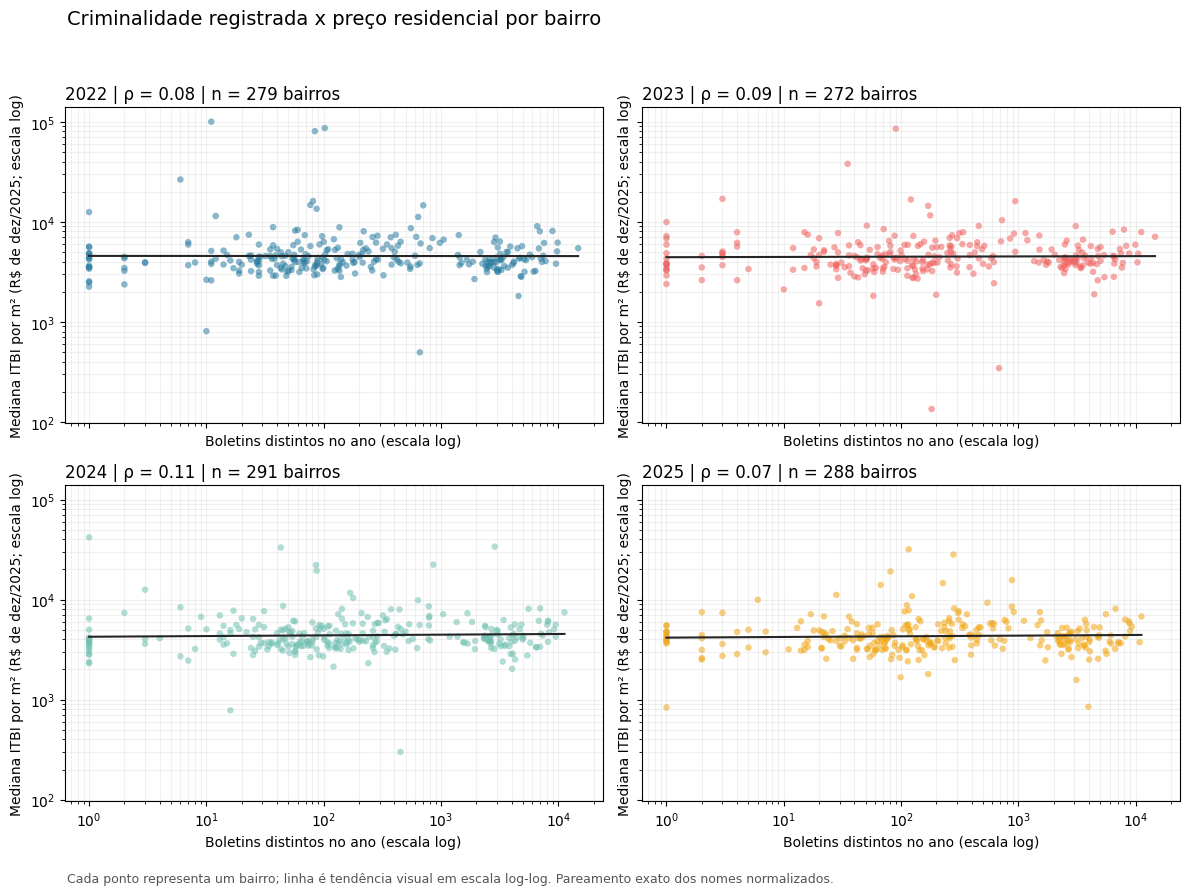

Bairros-ano com maiores medianas de preço por m² (R$ de dez/2025):


,ano,bairro,preco_m2_mediano,crimes,transacoes
409,2022.0,JARDIM TRUSSARDI,100140.3,11,12
616,2022.0,PIQUERI,86572.6,102,73
1101,2023.0,VILA TALARICO,85340.5,90,13
1040,2022.0,VILA PROGREDIOR,80527.1,84,45
1117,2024.0,VL ARICANDUVA,41893.2,1,84
365,2023.0,JARDIM JABAQUARA,37993.5,35,13
1095,2024.0,VILA SONIA,33788.0,2869,112
366,2024.0,JARDIM JABAQUARA,33148.3,43,11
380,2025.0,JARDIM ORIENTAL,31829.8,116,20
770,2025.0,VILA ARICANDUVA,28222.1,279,80


Bairros-ano com maior número de BOs:


,ano,bairro,crimes,preco_m2_mediano,transacoes
649,2022.0,REPUBLICA,14741,5443.8,28
650,2023.0,REPUBLICA,14593,7089.5,13
614,2024.0,PINHEIROS,11260,7455.2,531
615,2025.0,PINHEIROS,11165,6774.2,549
613,2023.0,PINHEIROS,11144,7894.3,465
85,2025.0,BRAS,10793,3744.8,110
59,2023.0,BELA VISTA,10482,4796.9,504
83,2023.0,BRAS,10340,3936.2,98
224,2023.0,CONSOLACAO,9918,5906.8,284
223,2022.0,CONSOLACAO,9857,6188.8,287


In [6]:
def correlacao_spearman(frame, x, y):
    ranks = frame[[x, y]].rank(method="average")
    return ranks[x].corr(ranks[y])


def rho_dentro_ano(frame):
    ranked = frame.copy()
    ranked["rank_preco"] = ranked.groupby("ano")["preco_m2_mediano"].rank(pct=True)
    ranked["rank_crime"] = ranked.groupby("ano")["crimes"].rank(pct=True)
    return ranked["rank_preco"].corr(ranked["rank_crime"])


def bootstrap_bairros(frame, statistic, n_boot=1000, seed=42):
    bairro_groups = {name: group for name, group in frame.groupby("bairro", sort=False)}
    bairros = np.array(list(bairro_groups))
    rng = np.random.default_rng(seed)
    estimates = []
    for _ in range(n_boot):
        sampled = rng.choice(bairros, size=len(bairros), replace=True)
        sample = pd.concat([bairro_groups[name] for name in sampled], ignore_index=True)
        estimate = statistic(sample)
        if pd.notna(estimate):
            estimates.append(estimate)
    return np.percentile(estimates, [2.5, 97.5])


annual_rows = []
for year, frame in analise.groupby("ano"):
    rho = correlacao_spearman(frame, "crimes", "preco_m2_mediano")
    low, high = bootstrap_bairros(
        frame, lambda sample: correlacao_spearman(sample, "crimes", "preco_m2_mediano"),
        seed=42 + int(year),
    )
    annual_rows.append({"ano": int(year), "bairros": frame["bairro"].nunique(), "rho_spearman": rho,
                        "ic95_inf": low, "ic95_sup": high})

rho_pooled = rho_dentro_ano(analise)
pooled_low, pooled_high = bootstrap_bairros(analise, rho_dentro_ano, seed=2026)
resultados = pd.DataFrame(annual_rows).set_index("ano")
display(resultados.round(3))
print(
    f"Associação combinada dentro do ano: ρ = {rho_pooled:.3f}; "
    f"IC 95% bootstrap por bairro [{pooled_low:.3f}, {pooled_high:.3f}]; "
    f"{analise['bairro'].nunique()} bairros, {len(analise)} observações bairro-ano."
)

fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)
for ax, (year, frame) in zip(axes.flat, analise.groupby("ano")):
    ax.scatter(frame["crimes"], frame["preco_m2_mediano"], s=22, alpha=0.55,
               color=["#247ba0", "#f25f5c", "#70c1b3", "#f3a712"][int(year) - YEARS[0]],
               edgecolors="none")
    positive = frame[(frame["crimes"] > 0) & (frame["preco_m2_mediano"] > 0)]
    log_x = np.log(positive["crimes"])
    log_y = np.log(positive["preco_m2_mediano"])
    slope, intercept = np.polyfit(log_x, log_y, 1)
    x_grid = np.geomspace(positive["crimes"].min(), positive["crimes"].max(), 100)
    ax.plot(x_grid, np.exp(intercept + slope * np.log(x_grid)), color="#252525", linewidth=1.5)
    rho = resultados.loc[int(year), "rho_spearman"]
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"{int(year)} | ρ = {rho:.2f} | n = {len(frame)} bairros", loc="left")
    ax.set_xlabel("Boletins distintos no ano (escala log)")
    ax.set_ylabel("Mediana ITBI por m² (R$ de dez/2025; escala log)")
    ax.grid(True, which="both", alpha=0.18)
fig.suptitle("Criminalidade registrada x preço residencial por bairro", x=0.06, ha="left", fontsize=14)
fig.text(0.06, 0.01, "Cada ponto representa um bairro; linha é tendência visual em escala log-log. Pareamento exato dos nomes normalizados.",
         fontsize=9, color="#555555")
plt.tight_layout(rect=(0, 0.03, 1, 0.95))
plt.show()

# Ranking descritivo para orientar a leitura, não para atribuir causalidade.
print("Bairros-ano com maiores medianas de preço por m² (R$ de dez/2025):")
display(analise.sort_values("preco_m2_mediano", ascending=False)[
    ["ano", "bairro", "preco_m2_mediano", "crimes", "transacoes"]
].head(10).round(1))
print("Bairros-ano com maior número de BOs:")
display(analise.sort_values("crimes", ascending=False)[
    ["ano", "bairro", "crimes", "preco_m2_mediano", "transacoes"]
].head(10).round(1))

## Conclusão exploratória

Os preços foram trazidos para reais de dezembro de 2025 pelo IPCA acumulado de fechamento anual. A mediana por m² nos bairros pareados ficou em torno de R$ 4,2 mil em 2022, R$ 4,3 mil em 2023 e R$ 4,1 mil em 2024 e 2025, sugerindo que parte da alta nominal entre anos era inflação, não valorização real equivalente. O fator anual é uma aproximação: não corrige a inflação exata entre o mês de cada transação e dezembro de 2025.

A correlação combinada dentro de cada ano é positiva, mas muito fraca (Spearman ρ = 0,087; IC 95% bootstrap por bairro: 0,003 a 0,180). Separadamente, em 2022–2025, as correlações variam de 0,074 a 0,113 e todos os ICs incluem zero. Como a correção pelo IPCA multiplica todos os preços de um mesmo ano pelo mesmo fator, ela não altera essas correlações anuais nem os rankings relativos usados nos clusters.

A correspondência exata de bairros cobre 40,2% das transações residenciais válidas e pode favorecer bairros com grafia mais consistente. Além disso, contagens de BO refletem também população, circulação e registro de ocorrências. Sem taxas por população, ajuste espacial confiável, controles socioeconômicos e características dos imóveis, estes resultados não permitem concluir que criminalidade impacta causalmente o valor do imóvel.

## Merge no nível da transação e clusters de bairros

O merge abaixo anexa a cada transação ITBI a contagem de BOs do mesmo bairro e ano. Transações sem correspondência permanecem na tabela, com crime ausente. Para segmentar regiões, usamos K-means com quatro grupos sobre os percentis anuais de preço por m² corrigido pelo IPCA e número de BOs; os percentis reduzem diferenças de nível entre anos. Cada ponto do gráfico é um bairro-ano, não uma transação individual.

Merge transação a transação: 254,915 linhas (igual ao ITBI filtrado: 254,915)
Transações com crime associado: 109,305 (42.9%)
Silhouette dos 4 clusters: 0.412


,perfil,bairros_ano,bairros_distintos,transacoes,preco_m2_mediano,crimes_medianos,percentil_preco,percentil_crime
0,Crime baixo | preço alto,271,135,9585,4998.552,40.0,0.706,0.240
1,Crime alto | preço baixo,285,108,32671,3768.819,2416.0,0.327,0.781
2,Crime baixo | preço baixo,288,155,7231,3403.648,48.0,0.191,0.268
3,Crime alto | preço alto,286,111,53112,5620.340,798.0,0.791,0.715


,bairro,ano,preco_m2,preco_m2_dez2025,crimes,cluster,perfil_cluster
6,VILA MADALENA,2022.0,5071.766667,5799.322855,261.0,3.0,Crime alto | preço alto
10,LAPA,2022.0,5256.410256,6010.453978,4480.0,3.0,Crime alto | preço alto
11,JARAGUA,2022.0,2940.953248,3362.839521,3269.0,1.0,Crime alto | preço baixo
12,VILA ANDRADE,2022.0,3195.876289,3654.331838,2820.0,1.0,Crime alto | preço baixo
13,VILA ANDRADE,2022.0,3148.148148,3599.756990,2820.0,1.0,Crime alto | preço baixo


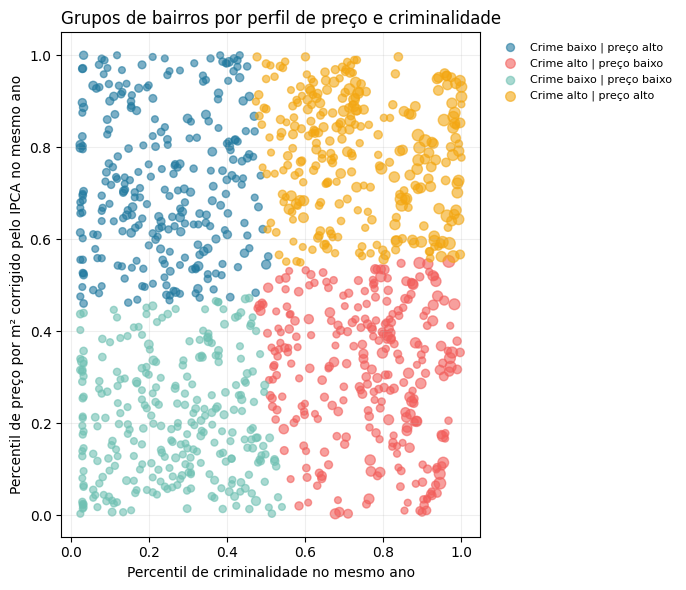

Médias dos percentis por cluster e ano:


percentil_crime_ano                           \
perfil_cluster Crime alto | preço alto Crime alto | preço baixo   
ano                                                               
2022.0                            0.74                     0.76   
2023.0                            0.73                     0.77   
2024.0                            0.75                     0.75   
2025.0                            0.74                     0.76   

                                                                   \
perfil_cluster Crime baixo | preço alto Crime baixo | preço baixo   
ano                                                                 
2022.0                             0.25                      0.25   
2023.0                             0.23                      0.27   
2024.0                             0.23                      0.26   
2025.0                             0.23                      0.26   

                   percentil_preco_ano                           \
perfil_cluster Crime alto | preço alto Crime alto | preço baixo   
ano                                                               
2022.0                            0.79                     0.31   
2023.0                            0.78                     0.32   
2024.0                            0.78                     0.31   
2025.0                            0.78                     0.30   

                                                                   
perfil_cluster Crime baixo | preço alto Crime baixo | preço baixo  
ano                                                                
2022.0                             0.73                      0.21  
2023.0                             0.73                      0.20  
2024.0                             0.73                      0.21  
2025.0                             0.71                      0.20

In [7]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Um vetor de características por bairro-ano, sem repetir bairros com mais transações.
clusters = analise[["bairro", "ano", "preco_m2_mediano", "crimes", "transacoes"]].copy()
clusters["percentil_preco_ano"] = clusters.groupby("ano")["preco_m2_mediano"].rank(pct=True)
clusters["percentil_crime_ano"] = clusters.groupby("ano")["crimes"].rank(pct=True)
X_cluster = clusters[["percentil_preco_ano", "percentil_crime_ano"]]

N_CLUSTERS = 4
modelo_clusters = KMeans(n_clusters=N_CLUSTERS, n_init=20, random_state=42)
clusters["cluster"] = modelo_clusters.fit_predict(X_cluster)
silhueta = silhouette_score(X_cluster, clusters["cluster"])

perfil_clusters = (
    clusters.groupby("cluster", as_index=False)
    .agg(
        bairros_ano=("bairro", "size"),
        bairros_distintos=("bairro", "nunique"),
        transacoes=("transacoes", "sum"),
        preco_m2_mediano=("preco_m2_mediano", "median"),
        crimes_medianos=("crimes", "median"),
        percentil_preco=("percentil_preco_ano", "median"),
        percentil_crime=("percentil_crime_ano", "median"),
    )
)
perfil_clusters["perfil"] = perfil_clusters.apply(
    lambda row: (
        f"Crime {'alto' if row['percentil_crime'] >= 0.5 else 'baixo'}"
        f" | preço {'alto' if row['percentil_preco'] >= 0.5 else 'baixo'}"
    ),
    axis=1,
)
mapa_perfil = perfil_clusters.set_index("cluster")["perfil"]
clusters["perfil_cluster"] = clusters["cluster"].map(mapa_perfil)

# Merge transação a transação; muitos imóveis podem pertencer ao mesmo bairro-ano.
imoveis_crimes = itbi_analise.merge(
    crime_bairro_ano, on=["bairro", "ano"], how="left", validate="many_to_one", indicator="merge_crime"
).merge(
    clusters[["bairro", "ano", "cluster", "perfil_cluster"]],
    on=["bairro", "ano"], how="left", validate="many_to_one",
)
pareadas = imoveis_crimes["merge_crime"].eq("both")
print(f"Merge transação a transação: {len(imoveis_crimes):,} linhas (igual ao ITBI filtrado: {len(itbi_analise):,})")
print(f"Transações com crime associado: {pareadas.sum():,} ({pareadas.mean():.1%})")
print(f"Silhouette dos {N_CLUSTERS} clusters: {silhueta:.3f}")
display(perfil_clusters[["perfil", "bairros_ano", "bairros_distintos", "transacoes", "preco_m2_mediano",
                         "crimes_medianos", "percentil_preco", "percentil_crime"]].round(3))

display(imoveis_crimes.loc[pareadas, ["bairro", "ano", "preco_m2", "preco_m2_dez2025", "crimes", "cluster", "perfil_cluster"]].head())

fig, ax = plt.subplots(figsize=(9, 6))
cores_cluster = ["#247ba0", "#f25f5c", "#70c1b3", "#f3a712"]
for _, perfil in perfil_clusters.iterrows():
    grupo = clusters[clusters["cluster"] == perfil["cluster"]]
    ax.scatter(grupo["percentil_crime_ano"], grupo["percentil_preco_ano"],
               s=18 + 55 * np.sqrt(grupo["transacoes"] / clusters["transacoes"].max()),
               alpha=0.6, color=cores_cluster[int(perfil["cluster"])], label=perfil["perfil"])
ax.set_xlabel("Percentil de criminalidade no mesmo ano")
ax.set_ylabel("Percentil de preço por m² corrigido pelo IPCA no mesmo ano")
ax.set_title("Grupos de bairros por perfil de preço e criminalidade", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.02, 1))
ax.grid(alpha=0.2)
plt.tight_layout(rect=(0, 0, 0.78, 1))
plt.show()

print("Médias dos percentis por cluster e ano:")
display(clusters.pivot_table(index="ano", columns="perfil_cluster",
                             values=["percentil_crime_ano", "percentil_preco_ano"], aggfunc="mean").round(2))